# Lab 4 — convolution: resolution and weight sharing

**Deep Learning 2026, semester project. 90 minutes.**

The network of the previous lab looked at 64 × 64 grey levels, had a million
parameters, and ended worse than predicting the mean. The model answer named
two causes: at 64 px a letter is under one pixel tall, and a multilayer
perceptron cannot reuse a detector it learned at one position anywhere else.
Today you fix both with a convolutional network, trained from scratch, on your
laptop. You also build what every later network of the semester will use: the
checks before training and the lecture's starting configuration for the
optimiser.

**How this notebook works.** As in lab 3: the code lives in `src/`, a cell
marked **TASK** names a file and a function, you write it, rerun the cell.
Three tasks, about 28 lines, and two training runs of one to six minutes each
on a laptop CPU: start the run, then we talk while it trains.

**Two kinds of cells.**

* **Core**: everything not marked otherwise. Everyone runs it, on a CPU, in
  the 90 minutes.
* **⭐ EXTRA**: for GPU owners and for whoever is ahead. Each extra cell has
  its own switch on its first line, `RUN = EXTRA`. **On a GPU, `EXTRA` is
  `True` and the extra cells run by themselves, in seconds.** On a CPU it is
  `False`: the cell prints the instructor's results instead, and you can set
  `RUN = True` in that one cell if you have the time it states. Skipping an
  extra cell costs nothing later: no core cell needs it.

| ⭐ EXTRA | what | CPU | GPU |
|---|---|---|---|
| E1 | TASK 4, augmentation that keeps the label, and its run (on a GPU also jitter and blur) | 4–8 min | 1 min |
| E2 | the learning-rate range test | 1–2 min | 5 s |
| E3 | the other checks and rungs: shuffled labels, best epoch, weight decay, GroupNorm, your `ResBlock` | 25–40 min | 2 min |

**Three stops, by the clock**: **0:30**, **0:50**, **1:10**. Each opens with
a question on the slide, answered by show of hands *before* the cell that
settles it. If you have not finished a task at a stop, the reference lines go
on the screen and you paste them.

| time | part | core | ⭐ EXTRA |
|---|---|---|---|
| 0:00–0:10 | 1 | the split and the baselines again; what 256 px shows | |
| 0:10–0:30 | 1 | TASK 1 the network, TASK 2 the checks, TASK 3 the optimiser — **stop 1** at 0:30, run 1 | |
| 0:30–0:50 | 2 | the same network at 768 px, through a wider stride — **stop 2** at 0:50, run 2 | E2 |
| 0:50–1:10 | 3 | regularisation in the lecture's order; which augmentation keeps the label — **stop 3** at 1:10 | E1, E3 |
| 1:10–1:30 | 4 | where the error lives; commit, push | |

**Before the lab**, at home: your lab-3 repository is committed and pushed,
the lab-4 files are copied in (the README of `lab_4_cnn` says how and which
files must appear in `git status`), `python -m src.data.inputs` has built the
256 and 768 px tables, and `pytest tests/test_lab4.py` fails with
`NotImplementedError` in every test and nothing else (the `augment` tests
belong to the extra TASK 4 and may keep failing).

In [1]:
import importlib
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image

from src import config, evaluate
from src.data import splits
from src.data.dataset import build_cache, cache_dir, load_table
from src.data.inputs import grey_table
from src.features import handcrafted
from src.models import baseline

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 4)

GPU = torch.cuda.is_available()
EXTRA = GPU or os.environ.get("RUN_ALL") == "1"    # ⭐ EXTRA cells: on by themselves on a GPU, off on a CPU
print("torch ", torch.__version__, "| GPU: the ⭐ EXTRA cells will run" if GPU else
      "| CPU: core runs take minutes; ⭐ EXTRA cells off (switch one on with RUN = True in that cell)",
      "| threads", torch.get_num_threads())
print("wandb ", "key set" if os.environ.get("WANDB_API_KEY") else "no key: anonymous runs",
      "/ mode", os.environ.get("WANDB_MODE", "online"))


def load_cfg(name):
    return yaml.safe_load(open(config.ROOT / "configs" / name))


cfg = load_cfg("lab4_small_cnn.yaml")
df = load_table()
if len(list(cache_dir(768).glob("*.jpg"))) < len(df):
    print("building the 768 px cache, a few minutes ...")
    build_cache(df, 768)
y_all = df[config.TARGET].to_numpy()

torch  2.4.1+cu124 | CPU: core runs take minutes; ⭐ EXTRA cells off (switch one on with RUN = True in that cell) | threads 8
wandb  key set / mode online


## Part 1 (0:00–0:30) — a convolutional network on four times the pixels

The same split as in lab 3 (strict unit 4 held out), the constant predictor,
and the gradient-boosting baseline on seven handcrafted features. These are
the numbers to beat. Lab 3's pixel MLP is quoted from the trial; yours was
within 0.01 of it.

In [2]:
SPLIT = cfg["split"]
train_idx, val_idx = splits.build_splits(df, SPLIT["group_column"], SPLIT["val_fraction"], SPLIT["seed"])
val_df = df.iloc[val_idx]
ok = (val_df["eval_ok"] == 1).to_numpy()
y_val = val_df[config.TARGET].to_numpy()
pages = val_df["page_id"].to_numpy()
prior = float(y_all[train_idx].mean())
assert sorted(val_df["group_strict"].unique()) == [4], "the room holds out strict unit 4: check TASK 1 of lab 3"

F = handcrafted.feature_table(df)
gbm = baseline.fit_baseline(F.iloc[train_idx], y_all[train_idx])
PRED = {"gradient boosting, 7 features": baseline.predict_baseline(gbm, F.iloc[val_idx])}
RESULTS = {"constant": evaluate.rmse(y_val[ok], np.full(ok.sum(), prior)),
           "gradient boosting, 7 features": evaluate.rmse(y_val[ok], PRED["gradient boosting, 7 features"][ok]),
           "lab 3: MLP on 64 px (trial)": 0.2587}
pd.Series(RESULTS, name="val RMSE").to_frame()

,val RMSE
constant,0.2362
"gradient boosting, 7 features",0.1732
lab 3: MLP on 64 px (trial),0.2587


**What 256 px shows.** One photograph, the same small window of the page
(a tenth of its width) at four resolutions. The network of today reads the
second panel first and the third later. The fourth is what the OCR engine
read when it produced the label.

9 pt letter height: 64 px: 0.7   256 px: 2.7   768 px: 8.2   2048 px: 21.9


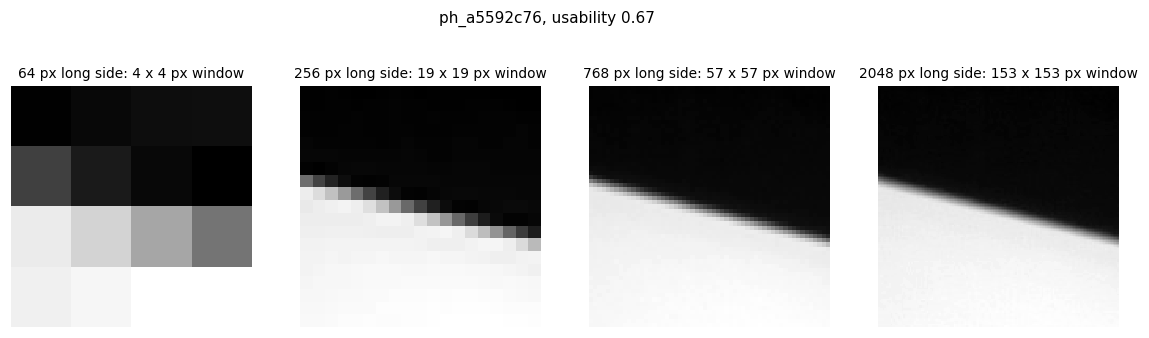

input table (1841, 1, 256, 256), uint8, 121 MB


In [3]:
A4_LONG_MM, PT_MM = 297.0, 25.4 / 72
print("9 pt letter height:", "   ".join(f"{s} px: {9 * PT_MM * s / A4_LONG_MM:.1f}" for s in (64, 256, 768, 2048)))

def text_window(a, w):
    # top-left corner of the w x w window with the most contrast: where the text is
    best, at = -1.0, (0, 0)
    for top in range(0, a.shape[0] - w, max(1, w // 4)):
        for left in range(0, a.shape[1] - w, max(1, w // 4)):
            s = a[top:top + w, left:left + w].std()
            if s > best:
                best, at = s, (top, left)
    return at


row = val_df[ok].sort_values(config.TARGET).iloc[len(val_df[ok]) // 3]
full = Image.open(row["path"]).convert("L")
top, left = text_window(np.asarray(full, dtype=np.float32), full.width // 10)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, size in zip(axes, (64, 256, 768, 2048), strict=True):
    im = full.copy()
    im.thumbnail((size, size), Image.LANCZOS)
    f = im.width / full.width
    w = max(4, im.width // 10)
    t, l = int(top * f), int(left * f)
    ax.imshow(im.crop((l, t, l + w, t + w)), cmap="gray", interpolation="nearest")
    ax.set_title(f"{size} px long side: {w} x {w} px window", fontsize=9); ax.axis("off")
plt.suptitle(f"{row['image_id']}, usability {row[config.TARGET]:.2f}", y=1.02, fontsize=10); plt.show()

X256 = grey_table(df, 256)
print(f"input table {X256.shape}, {X256.dtype}, {X256.nbytes / 1e6:.0f} MB")

### TASK 1 — the network

Open `src/models/cnn.py` and write the class `SmallCNN`. It must build
**exactly this network** for the config of the first run
(`configs/lab4_small_cnn.yaml`: `widths: [8, 16, 32, 64]`, `stem_stride: 2`,
`stem_kernel: 5`, `pool: avgmax`, `norm: batch`, `dropout: 0.0`), shown here
for one grey 256 × 256 image:

| layer | what it is | output shape |
|---|---|---|
| input | one standardised grey image | 1 × 256 × 256 |
| stem | `conv_block(1, 8, stride=2, kernel=5)`: Conv2d 1→8, 5 × 5, stride 2, padding 2, no bias; BatchNorm2d(8); ReLU | 8 × 128 × 128 |
| block 1 | `conv_block(8, 16)`: Conv2d 8→16, 3 × 3, padding 1, no bias; BatchNorm2d(16); ReLU; then MaxPool2d(2) | 16 × 64 × 64 |
| block 2 | `conv_block(16, 32)` and MaxPool2d(2) | 32 × 32 × 32 |
| block 3 | `conv_block(32, 64)` and MaxPool2d(2) | 64 × 16 × 16 |
| global pool | `GlobalPool("avgmax")`: the mean and the maximum of each channel over the 16 × 16 positions, side by side | 128 |
| dropout | `nn.Dropout(0.0)` | 128 |
| head | `nn.Linear(128, 1)`, small weights, bias = logit(training mean) | 1 logit |

**24,761 parameters** in total; the check cell compares. The class does not
hard-code these numbers: it builds the same layers from its arguments
(`in_ch`, `widths`, `stem_stride`, `stem_kernel`, `pool`, `norm`, `dropout`,
`prior`), so that the second run can change the input size and the stem
without a new class. The layers go into `self.features` (an `nn.Sequential`
of the stem and the three blocks), `self.pool`, `self.drop` and `self.head`,
in that order; then `init_weights(self)` and `prior_bias(self.head, prior)`.
`forward(x)` takes a batch of shape (batch, 1, H, W) and returns shape
(batch,): features, pool, dropout, head, `squeeze(1)`. **No sigmoid.** The
building blocks (`conv_block`, `GlobalPool`, `init_weights`, `prior_bias`)
are given at the top of the file.

Two things to notice in the numbers the cell prints. The parameter count:
lab 3's MLP had 1,065,345. And where the untrained network's predictions
sit: at the training mean, because the head's bias starts there, as in
lab 3.

**From now on models return logits.** The sigmoid belongs to the loss and to
the prediction (`src/losses.py` says why); `loss.predict` applies it.

In [4]:
from src import losses, sanity, train_cnn
from src.models import cnn
importlib.reload(cnn)

loss = losses.make_loss(cfg, y_all[train_idx])
batches = train_cnn.make_batches(X256, train_idx)          # standardised with training statistics


def make_net(c=cfg):
    mm = c["model"]
    return cnn.SmallCNN(in_ch=1, widths=mm["widths"], norm=mm["norm"], dropout=mm["dropout"], prior=prior,
                        stem_stride=mm["stem_stride"], stem_kernel=mm["stem_kernel"], pool=mm["pool"])


net = make_net()
xb, yb = batches.get(train_idx[:16], "cpu"), torch.as_tensor(y_all[train_idx[:16]], dtype=torch.float32)
p = sanity.check_output(net, xb, loss)
n_params = sum(q.numel() for q in net.parameters())
print(f"parameters {n_params:,} (lab 3's MLP: 1,065,345)   untrained predictions {np.round(p[:6].numpy(), 3)}   prior {prior:.3f}")
shapes, h = [], xb[:1]
with torch.no_grad():
    for k, layer in enumerate(net.features):
        h = layer(h)
        if k == 0 or isinstance(layer, torch.nn.MaxPool2d):        # after the stem, after each block
            shapes.append(tuple(h.shape[1:]))
print("after the stem and each block:", "  ".join(map(str, shapes)), " -> global pool:", tuple(net.pool(h).shape[1:]))
assert n_params == 24761, "not the network of the table: compare your layers with it, one by one"
print(net)

parameters 24,761 (lab 3's MLP: 1,065,345)   untrained predictions [0.758 0.757 0.758 0.758 0.758 0.757]   prior 0.759
after the stem and each block: (8, 128, 128)  (16, 64, 64)  (32, 32, 32)  (64, 16, 16)  -> global pool: (128,)
SmallCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 8, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2), bias=False)
      (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track

### TASK 2 — the checks before training

Open `src/sanity.py`. Two of the lecture's five checks are given
(`check_output`, the shape and range of one forward pass, which you just
used; `initial_loss`) and two are yours:

* `overfit_one_batch`: train on sixteen photographs and nothing else. A
  network that cannot drive the loss on sixteen images to nearly zero has a
  bug, and more data will not find it for you;
* `same_seed_twice`: two short runs from the same seed must give the same
  losses, or comparing two runs means nothing.

The fifth check, shuffled labels, is a whole training run: it is in ⭐ EXTRA
E3. The cell also estimates the **memory** of one training step, before
running anything: AdamW in float32 keeps four numbers per parameter (the
weight, its gradient, two moment estimates), 16 bytes each parameter; the
activations of every layer are kept for the backward pass and grow with the
batch and with the pixels.

,parameters,params+grads+adamw MB,activations MB,batch,activations per image MB,input batch MB
"256 px, batch 32",24761.0,0.4,241.21,32.0,7.54,8.39


initial loss 0.1174   loss of the training mean on this batch 0.1178   (variance of y: 0.0547)
overfit one batch: 0.1178 -> 0.000121 in 10 s   same seed twice: largest difference 0.00e+00


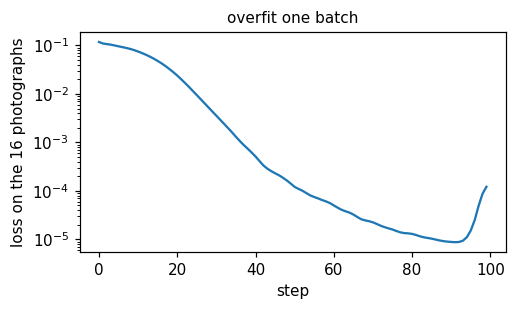

In [6]:
importlib.reload(sanity)
mem = pd.DataFrame({"256 px, batch 32": sanity.memory_estimate(net, batches.get(train_idx[:32], "cpu"))}).T
display(mem.round(2))

untrained, constant = sanity.initial_loss(net, xb, yb, loss)
print(f"initial loss {untrained:.4f}   loss of the training mean on this batch {constant:.4f}   (variance of y: {y_all[train_idx].var():.4f})")

t0 = time.time()
hist = sanity.overfit_one_batch(make_net(), xb, yb, loss, steps=100)
a, b = sanity.same_seed_twice(make_net, xb[:4], yb[:4], loss, seed=0, steps=5)
print(f"overfit one batch: {hist[0]:.4f} -> {hist[-1]:.6f} in {time.time() - t0:.0f} s"
      f"   same seed twice: largest difference {sanity.spread((a, b)):.2e}")
plt.figure(figsize=(5, 2.6)); plt.semilogy(hist); plt.xlabel("step"); plt.ylabel("loss on the 16 photographs")
plt.title("overfit one batch", fontsize=10); plt.show()
assert hist[-1] < 1e-3, "the network cannot memorise sixteen photographs: there is a bug"
assert sanity.spread((a, b)) < 1e-5, "two runs from the same seed differ"

### TASK 3 — the optimiser of the lecture's starting configuration

Open `src/optim.py` and write `param_groups`: AdamW gets two groups, weight
decay on the convolution and linear weights, none on biases and
normalisation parameters. The rest of the starting configuration is given and
switched on in the config: linear warmup then cosine decay
(`schedule: warmup_cosine`), gradient clipping at norm 1, and the order of
one step, `zero_grad → forward → loss → backward → clip → step → scheduler step`
(read `train_epoch` in `src/train_cnn.py`, about forty lines). The cell
shows the two groups and the learning rate the run will follow.

weight decay 0.05     5 tensors   24,520 numbers  shapes e.g. [(8, 1, 5, 5), (16, 8, 3, 3), (32, 16, 3, 3)]
weight decay 0.0      9 tensors      241 numbers  shapes e.g. [(8,), (8,), (16,)]


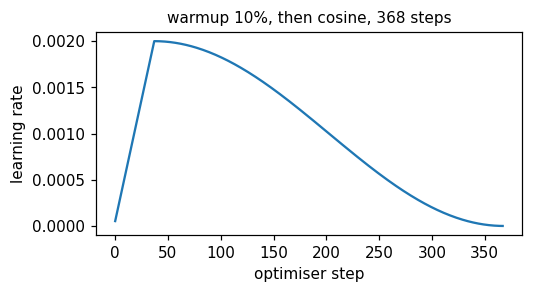

In [7]:
from src import optim
importlib.reload(optim)
groups = optim.param_groups(net, cfg["train"]["weight_decay"])
for g in groups:
    print(f"weight decay {g['weight_decay']:<5}  {len(g['params']):3d} tensors  {sum(q.numel() for q in g['params']):7,d} numbers"
          f"  shapes e.g. {[tuple(q.shape) for q in g['params'][:3]]}")

steps = cfg["train"]["epochs"] * train_cnn.n_batches(len(train_idx), cfg["train"]["batch_size"])
dummy = torch.optim.AdamW([torch.zeros(1, requires_grad=True)], lr=cfg["train"]["lr"])
sched = optim.make_schedule(dummy, steps, cfg["train"])
lrs = []
for _ in range(steps):
    lrs.append(dummy.param_groups[0]["lr"]); dummy.step(); sched.step()
plt.figure(figsize=(5, 2.4)); plt.plot(lrs); plt.xlabel("optimiser step"); plt.ylabel("learning rate")
plt.title(f"warmup {cfg['train']['warmup_frac']:.0%}, then cosine, {steps} steps", fontsize=10); plt.show()

### Stop 1 (0:30) — memory, and the first result

The table above estimated the memory of one training step. The next cell
trains the network for eight epochs on 256 px inputs, logged to W&B, one to
three minutes on a laptop CPU.

> **Stop.** Hands up: two questions are on the slides. Answer both before you
> run the next cell.

lab4_small_cnn: 1461 train / 380 val rows, input (1, 256, 256), 24,761 parameters (24,761 trainable), cpu
epoch   1  train loss 0.0535  train RMSE 0.2314  val RMSE 0.2182  grad norm 0.418  lr 2.00e-03  10 s
epoch   2  train loss 0.0502  train RMSE 0.2241  val RMSE 0.2371  grad norm 0.493  lr 1.87e-03  11 s
epoch   3  train loss 0.0488  train RMSE 0.2209  val RMSE 0.2130  grad norm 0.492  lr 1.57e-03  11 s
epoch   4  train loss 0.0457  train RMSE 0.2138  val RMSE 0.2097  grad norm 0.427  lr 1.17e-03  11 s
epoch   5  train loss 0.0430  train RMSE 0.2073  val RMSE 0.2060  grad norm 0.471  lr 7.42e-04  11 s
epoch   6  train loss 0.0400  train RMSE 0.2000  val RMSE 0.2073  grad norm 0.404  lr 3.58e-04  11 s
epoch   7  train loss 0.0396  train RMSE 0.1990  val RMSE 0.2146  grad norm 0.521  lr 9.38e-05  11 s
epoch   8  train loss 0.0367  train RMSE 0.1916  val RMSE 0.2116  grad norm 0.428  lr 0.00e+00  10 s


epoch/data_wait,▅▄▃▁▇█▇▃
epoch/epoch,▁▂▃▄▅▆▇█
epoch/grad_norm,▂▆▆▂▅▁█▂
epoch/lr,██▇▅▄▂▁▁
epoch/seconds,▁▃▃▅▄▅█▂
epoch/train_loss,█▇▆▅▄▂▂▁
epoch/train_rmse,█▇▆▅▄▂▂▁
epoch/val_mae,▂█▁▂▁▂▂▂
epoch/val_rmse,▄█▃▂▁▁▃▂
final/bias,▁
+6,...



92 s   val RMSE 0.2116   run page: https://wandb.ai/anzgj8-bme/dl2026-docphoto/runs/ca6yna1o


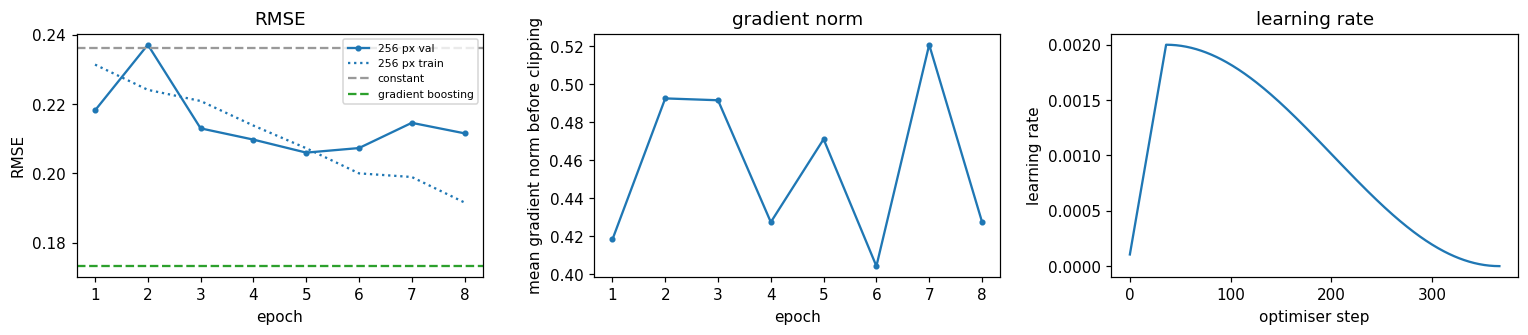

In [9]:
importlib.reload(train_cnn)
t0 = time.time()
run_a = train_cnn.train_model(cfg, X256, df, train_idx, val_idx)
RESULTS["CNN 256 px"] = evaluate.rmse(y_val[ok], run_a["val_pred"][ok])
PRED["CNN 256 px"] = run_a["val_pred"]
print(f"\n{time.time() - t0:.0f} s   val RMSE {RESULTS['CNN 256 px']:.4f}   run page: {run_a['url']}")


def curves(runs, title=""):
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
    for (name, r), c in zip(runs.items(), ("C0", "C1", "C2", "C3", "C4"), strict=False):
        h = r["history"]
        ax[0].plot(h["epoch"], h["val_rmse"], "-o", ms=3, color=c, label=f"{name} val")
        ax[0].plot(h["epoch"], h["train_rmse"], ":", color=c, label=f"{name} train")
        ax[1].plot(h["epoch"], h["grad_norm"], "-o", ms=3, color=c, label=name)
        ax[2].plot(r["lr_steps"], color=c, label=name)
    ax[0].axhline(RESULTS["constant"], color="0.6", ls="--", label="constant")
    ax[0].axhline(RESULTS["gradient boosting, 7 features"], color="C2", ls="--", label="gradient boosting")
    ax[0].set(xlabel="epoch", ylabel="RMSE", title="RMSE"); ax[0].legend(fontsize=7)
    ax[1].set(xlabel="epoch", ylabel="mean gradient norm before clipping", title="gradient norm")
    ax[2].set(xlabel="optimiser step", ylabel="learning rate", title="learning rate")
    plt.suptitle(title, y=1.02, fontsize=10); plt.tight_layout(); plt.show()


curves({"256 px": run_a})

> **Your note** (one or two sentences, before the stop):
>
> …

## Part 2 (0:30–0:50) — the same network, nine times the pixels

The features see 768 px. Give the network 768 px too, and pay for it in the
right place. A convolution's cost is (positions of its output map) × (input
channels) × (output channels) × (kernel area), so what decides the cost is
the size of the maps after the stem. The second config changes two numbers:
the input is 768 px instead of 256, and the stem's stride is 4 instead of 2
(with a 7 × 7 kernel, so that its windows still overlap). The stem's sixteen
filters therefore still see every one of the 590 thousand pixels at full
resolution; what they detect there (an edge, a stroke, a blur) survives in
their responses. Everything after the stem works on 192 px maps instead of
128 px ones: about twice the compute, nine times the information.

Estimate before you run: the cell counts the multiply-adds per image and the
memory of a training step for both configs.

In [10]:
cfg768 = load_cfg("lab4_cnn_768.yaml")
X768 = grey_table(df, 768)
batches768 = train_cnn.make_batches(X768, train_idx)
net768 = make_net(cfg768)
cost = pd.DataFrame({
    "256 px, stride 2": {**sanity.count_macs(net, batches.get(train_idx[:1], "cpu")),
                         **sanity.memory_estimate(net, batches.get(train_idx[:32], "cpu"))},
    "768 px, stride 4": {**sanity.count_macs(net768, batches768.get(train_idx[:1], "cpu")),
                         **sanity.memory_estimate(net768, batches768.get(train_idx[:32], "cpu"))},
}).T[["MMAC per image", "parameters", "params+grads+adamw MB", "activations MB", "input batch MB"]]
display(cost.round(1))
print(f"input table {X768.shape}, {X768.nbytes / 1e6:.0f} MB as bytes ({X768.nbytes * 4 / 1e9:.1f} GB it would take as floats)")

,MMAC per image,parameters,params+grads+adamw MB,activations MB,input batch MB
"256 px, stride 2",59.9,24761.0,0.4,241.2,8.4
"768 px, stride 4",141.9,24953.0,0.4,542.7,75.5


input table (1841, 1, 768, 768), 1086 MB as bytes (4.3 GB it would take as floats)


### Stop 2 (0:50) — what nine times the pixels buys

> **Stop.** Hands up: the question is on the slide. Answer it before you run
> the next cell (three to five minutes on a laptop CPU, seconds on a GPU).

lab4_cnn_768: 1461 train / 380 val rows, input (1, 768, 768), 24,953 parameters (24,953 trainable), cpu
epoch   1  train loss 0.0506  train RMSE 0.2250  val RMSE 0.2011  grad norm 0.494  lr 2.00e-03  39 s
epoch   2  train loss 0.0445  train RMSE 0.2109  val RMSE 0.1842  grad norm 0.516  lr 1.87e-03  39 s
epoch   3  train loss 0.0425  train RMSE 0.2063  val RMSE 0.1922  grad norm 0.569  lr 1.57e-03  42 s
epoch   4  train loss 0.0395  train RMSE 0.1987  val RMSE 0.1882  grad norm 0.469  lr 1.17e-03  43 s
epoch   5  train loss 0.0373  train RMSE 0.1931  val RMSE 0.1890  grad norm 0.548  lr 7.42e-04  41 s
epoch   6  train loss 0.0345  train RMSE 0.1857  val RMSE 0.1765  grad norm 0.517  lr 3.58e-04  41 s
epoch   7  train loss 0.0336  train RMSE 0.1834  val RMSE 0.1833  grad norm 0.519  lr 9.38e-05  42 s
epoch   8  train loss 0.0312  train RMSE 0.1766  val RMSE 0.1792  grad norm 0.527  lr 0.00e+00  41 s


epoch/data_wait,▁▇▅▆▆█▂▁
epoch/epoch,▁▂▃▄▅▆▇█
epoch/grad_norm,▃▄█▁▇▄▄▅
epoch/lr,██▇▅▄▂▁▁
epoch/seconds,▁▁▅█▄▃▆▅
epoch/train_loss,█▆▅▄▃▂▂▁
epoch/train_rmse,█▆▅▄▃▂▂▁
epoch/val_mae,█▃▆▂▅▁▁▂
epoch/val_rmse,█▃▅▄▅▁▃▂
final/bias,▁
+6,...



343 s   val RMSE 0.1792   run page: https://wandb.ai/anzgj8-bme/dl2026-docphoto/runs/k2niyy0q
768 minus 256: -0.0324, 95 % interval over pages [-0.0464, -0.0158], 768 better in 100% of resamples


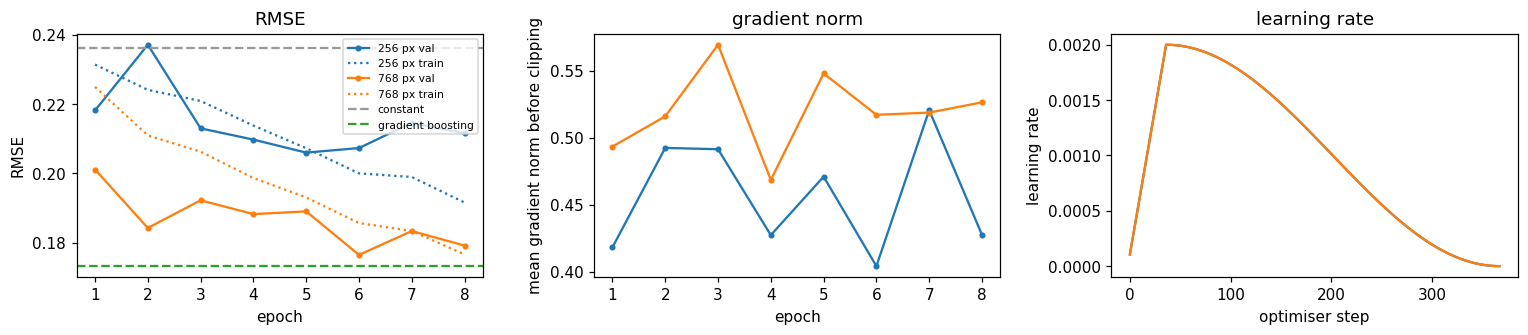

In [11]:
t0 = time.time()
run_b = train_cnn.train_model(cfg768, X768, df, train_idx, val_idx)
RESULTS["CNN 768 px, stride-4 stem"] = evaluate.rmse(y_val[ok], run_b["val_pred"][ok])
PRED["CNN 768 px, stride-4 stem"] = run_b["val_pred"]
cmp = evaluate.page_bootstrap(y_val[ok], PRED["CNN 256 px"][ok], run_b["val_pred"][ok], pages[ok])
print(f"\n{time.time() - t0:.0f} s   val RMSE {RESULTS['CNN 768 px, stride-4 stem']:.4f}   run page: {run_b['url']}")
print(f"768 minus 256: {cmp['diff']:+.4f}, 95 % interval over pages [{cmp['lo']:+.4f}, {cmp['hi']:+.4f}], "
      f"768 better in {cmp['share_b_better']:.0%} of resamples")
curves({"256 px": run_a, "768 px": run_b})

> **Your note** (one or two sentences, before the stop):
>
> …

### ⭐ EXTRA E2 — the learning-rate range test

GPU: runs by itself, 5 seconds. CPU: 1 to 2 minutes, set `RUN = True`.

One epoch with the learning rate rising exponentially from 1e-6 to 1, one
batch per step, loss recorded. The loss falls once the rate is large enough
to learn and explodes once it is too large; a common rule takes a tenth of
the rate at the bottom of the smoothed curve. One W&B run.

In [ ]:
RUN = EXTRA            # ⭐ EXTRA E2: set to True to run it on a CPU (1 to 2 minutes)
if RUN:
    curve, suggestion = train_cnn.lr_range_test(cfg768, X768, df, train_idx, steps=100)
    plt.figure(figsize=(5, 2.6)); plt.semilogx(curve["lr"], curve["smoothed"])
    plt.axvline(suggestion, color="C3", ls="--", label=f"suggested {suggestion:.1e}")
    plt.axvline(cfg768["train"]["lr"], color="0.5", ls=":", label=f"config {cfg768['train']['lr']:.0e}")
    plt.xlabel("learning rate"); plt.ylabel("smoothed loss"); plt.legend(fontsize=8); plt.show()
else:
    print("⭐ E2 skipped. In the trial the smoothed loss bottoms out near 1.6e-3 and explodes above 3e-2; "
          "the config runs at 2e-3.")

## Part 3 (0:50–1:10) — regularisation, in the lecture's order

The lecture's rule: **regularise only after the model overfits**, and then in
this order: augmentation, early stopping on the best checkpoint, weight
decay, dropout. Before reaching for any of them, look at whether this model
overfits: the cell puts the training and validation RMSE of the 768 px run
side by side, epoch by epoch. Overfitting is the training RMSE falling while
the validation RMSE stays or rises.

In [ ]:
h = run_b["history"][["epoch", "train_rmse", "val_rmse"]].copy()
h["val minus train"] = h["val_rmse"] - h["train_rmse"]
display(h.set_index("epoch").round(4))

The first rung, augmentation, has a trap on this task that no other
regulariser has. Augmentation shows the network variations of each training
photograph *that leave the label unchanged*. Here the label is how readable
the page is. `src/data/augment.py` has two standard ImageNet augmentations,
brightness and contrast jitter and blur, and (TASK 4, ⭐ EXTRA E1) a mirror
with a small shift. The cell shows four training photographs through each.
Look at the crops on the bottom row and ask of each column: **is this still
the same label?**

In [ ]:
from src.data import augment
importlib.reload(augment)
pick = train_idx[np.argsort(y_all[train_idx])[[-40, -200, 300, 40]]]
x4 = batches768.get(pick, "cpu")
centre = x4[0, 0, :, 324:444].numpy()             # a band around the vertical axis: a mirror maps it onto itself
top = max(range(0, 768 - 120, 20), key=lambda t: centre[t:t + 120].std())
outs = {"original": x4}
for name, f in (("flip + shift (TASK 4)", augment.augment_safe), ("brightness jitter", augment.augment_jitter),
                ("blur", augment.augment_blur)):
    try:
        outs[name] = f(x4, torch.Generator().manual_seed(0), fill=batches768.fill)
    except NotImplementedError:
        pass                                      # TASK 4 is extra: without it the column is left out
fig, axes = plt.subplots(2, len(outs), figsize=(3.3 * len(outs), 6))
for j, (name, x) in enumerate(outs.items()):
    axes[0, j].imshow(x[0, 0], cmap="gray", vmin=-2.5, vmax=1.5); axes[0, j].set_title(name, fontsize=10)
    axes[1, j].imshow(x[0, 0, top:top + 120, 324:444], cmap="gray", vmin=-2.5, vmax=1.5, interpolation="nearest")
    axes[1, j].set_title("120 px crop", fontsize=9)
for a in axes.flat:
    a.axis("off")
plt.suptitle(f"usability of this photograph: {y_all[pick[0]]:.2f}", y=1.0); plt.show()

### Stop 3 (1:10) — which augmentation, and how sure are we

The cell shows what the instructor's trial measured: the 768 px network
trained with each augmentation, three seeds each, against no augmentation.
If you ran ⭐ EXTRA E1, your own runs are compared below it with the paired
page bootstrap.

> **Stop.** Hands up: the question is on the slide. Answer it before you run
> the next cell.

In [ ]:
TRIAL = {   # the instructor's trial: mean of three seeds, 8 epochs, validation = strict unit 4
    "CNN 256 px": 0.212, "CNN 768 px, stride-4 stem": 0.175,
    "  + safe (flip, shift)": 0.174, "  + brightness jitter": 0.175, "  + blur": 0.208,
    "  + safe, 12 epochs": 0.168,
}

display(pd.DataFrame({"val RMSE, mean of 3 seeds": {k.strip(" +"): v for k, v in TRIAL.items() if "768" in k or "+" in k}}))

> **Your note** (one or two sentences, before the stop):
>
> …

### ⭐ EXTRA E1 — TASK 4, augmentation that keeps the label

GPU: runs by itself, about a minute (three runs). CPU: 4 to 8 minutes for the
one run with your augmentation, set `RUN = True`.

Open `src/data/augment.py` and write `augment_safe`: a random left-right
mirror and a random shift of up to 8 pixels, per image, reproducible from a
generator (the docstring gives the recipe; `tests/test_lab4.py` checks it).
The cell trains the 768 px network with it, the second run of the lab that
differs from another in exactly one thing, and compares the two with the
paired page bootstrap. On a GPU it also trains with jitter and with blur.

In [ ]:
RUN = EXTRA            # ⭐ EXTRA E1: set to True to run it on a CPU (4 to 8 minutes)
if RUN:
    rows = {"none": run_b}
    for aug in (("safe", "jitter", "blur") if GPU else ("safe",)):
        c = load_cfg("lab4_cnn_768.yaml")
        c["name"], c["train"]["augment"] = f"lab4_cnn_768_{aug}", aug
        rows[aug] = train_cnn.train_model(c, X768, df, train_idx, val_idx, log=lambda *a: None)
        RESULTS[f"CNN 768 px + {aug} augmentation"] = evaluate.rmse(y_val[ok], rows[aug]["val_pred"][ok])
        PRED[f"CNN 768 px + {aug} augmentation"] = rows[aug]["val_pred"]
    table = {}
    for name, r in rows.items():
        bs = evaluate.page_bootstrap(y_val[ok], run_b["val_pred"][ok], r["val_pred"][ok], pages[ok])
        table[name] = {"val RMSE": bs["rmse_b"], "minus none": bs["diff"], "95 % lo": bs["lo"], "95 % hi": bs["hi"],
                       "better than none in": bs["share_b_better"], "train RMSE": r["history"]["train_rmse"].iloc[-1]}
    display(pd.DataFrame(table).T.round(4))
    curves({name: r for name, r in rows.items()}, "768 px, by augmentation")
else:
    print("⭐ E1 skipped. The trial's numbers are in the table at stop 3.")

### ⭐ EXTRA E3 — the other checks and rungs

GPU: runs by itself, about 2 minutes. CPU: 25 to 40 minutes, set `RUN = True`
(or pick one change and run only that one).

Each a run at 768 px with one change, all logged to W&B:

* **shuffled labels**, the fifth check: trained on permuted targets, the
  network can only memorise; validation must stay at the constant;
* **keeping the best epoch** (`select: best`): how much the validation score
  improves when you pick the epoch on the same validation set (peeking);
* **weight decay** 0 and 0.5 instead of 0.05; **GroupNorm** instead of BatchNorm;
* **your `ResBlock`** (TASK ⭐ in `cnn.py`, a pre-norm residual block whose
  last convolution starts at zero): `resnet_small`, the same layout with a
  residual block in every stage. Skipped if `ResBlock` is not written.

In [ ]:
RUN = EXTRA            # ⭐ EXTRA E3: set to True to run it on a CPU (25 to 40 minutes)
if RUN:
    star = {}
    perm = y_all.copy()
    perm[train_idx] = np.random.default_rng(0).permutation(y_all[train_idx])
    c = load_cfg("lab4_cnn_768.yaml"); c["name"] = "lab4_shuffled_labels"
    star["shuffled labels"] = train_cnn.train_model(c, X768, df, train_idx, val_idx, y=perm, log=lambda *a: None)
    for label, (key, value) in {"select best (peeking)": ("train.select", "best"),
                                "weight decay 0": ("train.weight_decay", 0.0),
                                "weight decay 0.5": ("train.weight_decay", 0.5),
                                "GroupNorm": ("model.norm", "group"),
                                "resnet_small": ("model.type", "resnet_small")}.items():
        c = load_cfg("lab4_cnn_768.yaml")
        section, field = key.split(".")
        c[section][field] = value
        c["name"] = "lab4_" + label.replace(" ", "_").replace("(", "").replace(")", "")
        try:
            star[label] = train_cnn.train_model(c, X768, df, train_idx, val_idx, log=lambda *a: None)
        except NotImplementedError as e:
            print(f"{label}: skipped ({e})")
    display(pd.DataFrame({k: {"val RMSE": evaluate.rmse(y_val[ok], r["val_pred"][ok]),
                              "train RMSE": r["history"]["train_rmse"].iloc[-1],
                              "spread ratio": r["report"].loc["model", "spread ratio"]}
                          for k, r in star.items()}).T.round(4))
else:
    print("⭐ E3 skipped. The trial's numbers are on the slides.")

## Part 4 (1:10–1:30) — where the error lives

One number per model hides what to fix. The regression report from
`src/evaluate.py`, for the baseline and for your best network, side by side:

1. **predicted against true**: points on a horizontal band mean the model
   ignores the image; on the diagonal, right;
2. **residual against prediction**, with the mean residual per bin: a trend
   here is something left to learn;
3. **calibration**: the mean true value per bin of the prediction; on the
   diagonal, a prediction of 0.6 means 0.6 on average;
4. **residuals by document family**: who the model is too optimistic about.

The table under it puts RMSE, MAE, bias, the **spread ratio** (the standard
deviation of the predictions over that of the truth; below one, the model
does not dare to call a photograph bad) and Spearman next to the training
mean. The same report is on the W&B page of every run.

In [ ]:
table = pd.Series(RESULTS, name="val RMSE").to_frame()
table["vs constant"] = 1 - table["val RMSE"] / RESULTS["constant"]
display(table)

best = min((k for k in PRED if k.startswith("CNN")), key=lambda k: RESULTS[k])
for name in ("gradient boosting, 7 features", best):
    rep, fig = evaluate.regression_report(val_df[ok], y_val[ok], PRED[name][ok], baseline=prior, title=name)
    display(rep.round(4)); plt.show()

display(pd.concat({name: evaluate.by_slice(val_df[ok], PRED[name][ok], "family")["rmse"]
                   for name in ("gradient boosting, 7 features", best)}, axis=1))
w = evaluate.worst(val_df[ok], PRED[best][ok], k=5)
display(w)

# the validation photographs as a sample submission, for the predict.py homework
pd.DataFrame({"image_id": val_df["image_id"], "usability": 0.5}).to_csv(config.ROOT / "data" / "work" / "val_sample.csv", index=False)

> **Your note** (one or two sentences, before the stop):
>
> …

### Commit

```bash
git add -A
git commit -m "lab 4: a CNN from scratch, the checks, the starting configuration"
git push
```

Then run the cell below: `git status` must be empty and the commit on
`origin/main`. The checkpoints of today are in `models/` (not in git); the
runs and their configs are in W&B.

In [ ]:
!cd {config.ROOT} && git status --short && git log --oneline -3 && git branch -vv

### Homework

1. **`src/predict.py` for the CNN checkpoint.** This is what the next lab's
   first Kaggle submission runs on, so it must work before that lab. The
   pieces: `torch.load` the checkpoint; `losses.from_state(ckpt["loss_state"])`;
   `build_model(ckpt["config"], ckpt["in_shape"], loss)` from
   `src/models/build.py`, then `load_state_dict` and `eval()`; for each image
   `inputs.preprocess_one(path, cfg, ckpt)` (it rebuilds exactly what the
   training table held, from the original photograph); the model's output
   through `loss.predict`. Dry run on the validation unit:

   ```bash
   docker compose run --rm dev python -m src.predict --config configs/lab4_cnn_768.yaml \
       --checkpoint models/lab4_cnn_768.pt --test-dir data/raw/train \
       --sample data/work/val_sample.csv --out submissions/val_dryrun.csv
   ```

   and check that its RMSE on the scoreable rows equals the notebook's to
   four decimals. If it does not, your preprocessing differs from training.
2. **Longer.** 12 and 16 epochs at 768 px, with safe augmentation: does it
   start to overfit, and where? Report with the page bootstrap.
3. **The ⭐ EXTRA cells** you skipped, E1 (TASK 4) first, one change per run.
4. **Early stopping, honestly** (still open from lab 3 for most of you).